# 07 Does history predict the future?
**Question:** do users with similar history before a cut date T watch the same *new* series after T more than random users of similar activity? And does recommending what those neighbours watched beat recommending what was popular last week?

Setup: views of any depth count (θ not decided yet). History = series viewed before T. Future = series viewed after T that are not in the user's history. Neighbours = 20 most similar users by cosine on history. Random = 20 users from the same activity quintile.

In [1]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

ROOT = "../data/ContentWiseImpressions/data/ContentWiseImpressions/CW10M"
inter = pd.read_parquet(f"{ROOT}/interactions", columns=["user_id", "series_id", "interaction_type"]).reset_index()
views = inter[inter.interaction_type == 0].copy()
views["t"] = pd.to_datetime(views.utc_ts_milliseconds, unit="ms")
T = views.t.min() + (views.t.max() - views.t.min()) / 2
T

Timestamp('2019-02-25 09:00:00.500000')

In [2]:
users, series = pd.Index(views.user_id.unique()), pd.Index(views.series_id.unique())

def matrix(d):
    d = d.drop_duplicates(["user_id", "series_id"])
    return sp.csr_matrix((np.ones(len(d), np.float32), (users.get_indexer(d.user_id), series.get_indexer(d.series_id))),
                         shape=(len(users), len(series)))

H = matrix(views[views.t < T])
A = matrix(views[views.t >= T])
F = A - A.multiply(H)
F.eliminate_zeros()
h, f = np.asarray(H.sum(1)).ravel(), np.asarray(F.sum(1)).ravel()
elig = np.where((h > 0) & (f > 0))[0]
len(users), len(elig)

(42153, 33289)

In [3]:
bucket = pd.qcut(h[elig], 5, labels=False)
pd.Series(h[elig]).groupby(bucket).agg(["min", "max", "size"])

,min,max,size
0,1.0,3.0,6991
1,4.0,7.0,6866
2,8.0,13.0,6601
3,14.0,24.0,6375
4,25.0,470.0,6456


In [4]:
Hp, Fp, fsize = H[elig], F[elig], f[elig]
Hn = sp.diags(1 / np.sqrt(np.asarray(Hp.sum(1)).ravel())) @ Hp

last_week = views[(views.t < T) & (views.t >= T - pd.Timedelta(days=7))].drop_duplicates(["user_id", "series_id"])
pop = np.zeros(len(series), np.float32)
vc = last_week.series_id.value_counts()
pop[series.get_indexer(vc.index)] = vc.values

k, K = 20, 20
rng = np.random.default_rng(0)
by_bucket = {b: np.where(bucket == b)[0] for b in range(5)}

def recall(scores, seen, truth):
    scores = np.where(seen, -np.inf, scores)
    top = np.argpartition(-scores, K, axis=1)[:, :K]
    return np.take_along_axis(truth, top, 1).sum(1) / truth.sum(1)

def jaccard(FF, b, others):
    both = np.take_along_axis(FF, others, 1)
    return (both / (fsize[b, None] + fsize[others] - both)).mean(1)

rows = []
for s0 in range(0, len(elig), 2000):
    b = np.arange(s0, min(s0 + 2000, len(elig)))
    S = (Hn[b] @ Hn.T).toarray()
    S[np.arange(len(b)), b] = -1
    nn = np.argpartition(-S, k, axis=1)[:, :k]
    rnd = np.stack([rng.choice(by_bucket[bucket[i]], k) for i in b])
    FF = (Fp[b] @ Fp.T).toarray()
    W = sp.csr_matrix((np.take_along_axis(S, nn, 1).ravel(), (np.repeat(np.arange(len(b)), k), nn.ravel())),
                      shape=(len(b), len(elig)))
    seen, truth = Hp[b].toarray() > 0, Fp[b].toarray() > 0
    rows.append(pd.DataFrame({
        "bucket": bucket[b],
        "jac_neighbours": jaccard(FF, b, nn),
        "jac_random": jaccard(FF, b, rnd),
        "recall_knn": recall((W @ Hp).toarray(), seen, truth),
        "recall_popularity": recall(np.broadcast_to(pop, seen.shape), seen, truth),
    }))
res = pd.concat(rows)
g = res.groupby("bucket").mean()
g

/tmp/ipykernel_217501/1795576812.py:4: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  last_week = views[(views.t < T) & (views.t >= T - pd.Timedelta(days=7))].drop_duplicates(["user_id", "series_id"])


,jac_neighbours,jac_random,recall_knn,recall_popularity
bucket,,,,
0,0.009069,0.005030,0.068416,0.147675
1,0.009996,0.005009,0.072180,0.117693
2,0.012583,0.005474,0.085564,0.098272
3,0.020214,0.006774,0.084751,0.077085
4,0.038097,0.011167,0.068146,0.053036


### Persona: future overlap of history-neighbours vs random users

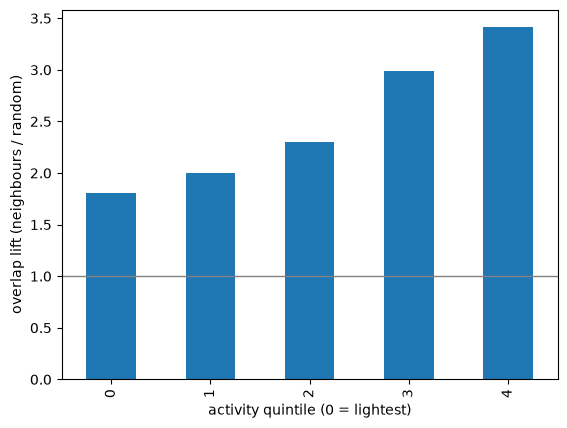

In [5]:
(g.jac_neighbours / g.jac_random).plot.bar(xlabel="activity quintile (0 = lightest)", ylabel="overlap lift (neighbours / random)")
plt.axhline(1, color="grey", lw=1)
plt.show()

### Usefulness: recall@20 of new series, neighbours vs last week's popularity

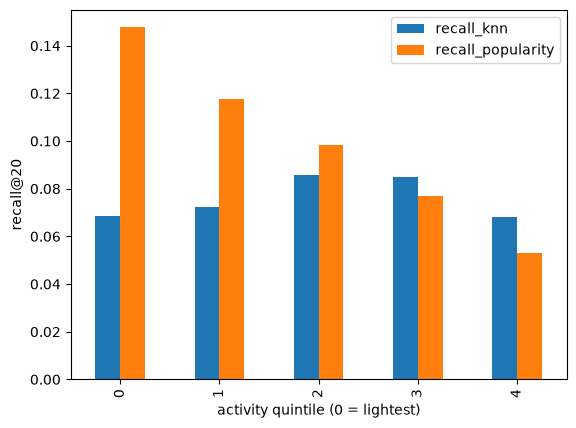

In [6]:
g[["recall_knn", "recall_popularity"]].plot.bar(xlabel="activity quintile (0 = lightest)", ylabel="recall@20")
plt.show()

In [7]:
res[['recall_knn', 'recall_popularity']].mean()

recall_knn           0.075669
recall_popularity    0.099822
dtype: float64

**Observation:** 

**Decision:** 